# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Team Screen Time Dataset](https://www.kaggle.com/datasets/vedauv/teen-screen-time-and-wellbeing-10k-synthetic/data?select=teen_screen_time.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.	

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

/kaggle/input/datasets/vedauv/teen-screen-time-and-wellbeing-10k-synthetic/README.md
/kaggle/input/datasets/vedauv/teen-screen-time-and-wellbeing-10k-synthetic/datasheet.md
/kaggle/input/datasets/vedauv/teen-screen-time-and-wellbeing-10k-synthetic/teen_screen_time.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('teen_screen_time.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,teen_id,age,gender,country,primary_platform,parental_controls,daily_screen_hours,social_media_hours,gaming_hours,night_phone_min,notifications_per_day,sleep_hours,physical_activity_min,close_friends,family_time_hours,school_grade_avg,anxiety_score,high_anxiety
0,T00001,15,Male,Nigeria,YouTube,1,6.8,3.3,1.2,50,64,7.3,3,7,4.0,54,9,1
1,T00002,19,Female,USA,YouTube,0,7.2,5.3,0.8,86,62,7.3,39,5,0.9,62,12,1
2,T00003,15,Female,Other,Discord,1,9.8,7.7,0.8,188,153,6.1,52,1,4.4,60,15,1
3,T00004,18,Male,Other,Snapchat,0,10.0,3.5,4.4,14,157,6.5,55,5,1.2,57,5,0
4,T00005,15,Male,Australia,YouTube,1,5.8,0.9,1.2,38,93,7.2,36,3,2.1,85,5,0


## last Five row

In [4]:
df.tail()

,teen_id,age,gender,country,primary_platform,parental_controls,daily_screen_hours,social_media_hours,gaming_hours,night_phone_min,notifications_per_day,sleep_hours,physical_activity_min,close_friends,family_time_hours,school_grade_avg,anxiety_score,high_anxiety
9995,T09996,13,Non-binary,USA,Instagram,0,10.1,6.4,0.4,39,98,6.8,164,4,0.5,60,5,0
9996,T09997,19,Male,USA,TikTok,0,12.7,5.2,2.9,19,28,6.3,17,5,1.0,52,6,0
9997,T09998,14,Female,UK,Instagram,1,6.4,4.1,0.8,71,133,8.3,70,3,1.1,80,4,0
9998,T09999,18,Female,Germany,Instagram,1,5.7,1.8,0.8,14,47,6.9,34,7,1.9,65,7,0
9999,T10000,16,Male,Other,Instagram,0,10.6,4.2,5.1,7,72,6.6,68,3,2.6,61,2,0


## Shape of our dataset

In [5]:
df.shape

(10000, 18)

## List out all columns

In [6]:
df.columns

Index(['teen_id', 'age', 'gender', 'country', 'primary_platform',
       'parental_controls', 'daily_screen_hours', 'social_media_hours',
       'gaming_hours', 'night_phone_min', 'notifications_per_day',
       'sleep_hours', 'physical_activity_min', 'close_friends',
       'family_time_hours', 'school_grade_avg', 'anxiety_score',
       'high_anxiety'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

teen_id                   object
age                        int64
gender                    object
country                   object
primary_platform          object
parental_controls          int64
daily_screen_hours       float64
social_media_hours       float64
gaming_hours             float64
night_phone_min            int64
notifications_per_day      int64
sleep_hours              float64
physical_activity_min      int64
close_friends              int64
family_time_hours        float64
school_grade_avg           int64
anxiety_score              int64
high_anxiety               int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   teen_id                10000 non-null  object 
 1   age                    10000 non-null  int64  
 2   gender                 10000 non-null  object 
 3   country                10000 non-null  object 
 4   primary_platform       9396 non-null   object 
 5   parental_controls      10000 non-null  int64  
 6   daily_screen_hours     10000 non-null  float64
 7   social_media_hours     10000 non-null  float64
 8   gaming_hours           10000 non-null  float64
 9   night_phone_min        10000 non-null  int64  
 10  notifications_per_day  10000 non-null  int64  
 11  sleep_hours            10000 non-null  float64
 12  physical_activity_min  10000 non-null  int64  
 13  close_friends          10000 non-null  int64  
 14  family_time_hours      10000 non-null  float64
 15  sch

## Check Null Value

In [9]:
df.isnull().sum()

teen_id                    0
age                        0
gender                     0
country                    0
primary_platform         604
parental_controls          0
daily_screen_hours         0
social_media_hours         0
gaming_hours               0
night_phone_min            0
notifications_per_day      0
sleep_hours                0
physical_activity_min      0
close_friends              0
family_time_hours          0
school_grade_avg           0
anxiety_score              0
high_anxiety               0
dtype: int64

## Drop Null Feacher

In [10]:
df.drop('primary_platform', axis=1, inplace=True)

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,age,parental_controls,daily_screen_hours,social_media_hours,gaming_hours,night_phone_min,notifications_per_day,sleep_hours,physical_activity_min,close_friends,family_time_hours,school_grade_avg,anxiety_score,high_anxiety
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,15.98070,0.497100,8.021080,2.989130,2.265650,39.563100,103.580000,7.402020,41.801300,5.004200,1.79389,67.658500,6.190700,0.250000
std,2.00303,0.500017,3.135366,1.942713,2.137908,38.352506,70.142535,0.775314,32.836383,2.220107,1.14207,9.814801,2.608144,0.433034
min,13.00000,0.000000,2.200000,0.200000,0.000000,1.000000,8.000000,4.000000,0.000000,0.000000,0.00000,35.000000,0.000000,0.000000
25%,14.00000,0.000000,5.700000,1.675000,0.800000,15.000000,57.000000,6.900000,18.000000,3.000000,1.00000,61.000000,4.000000,0.000000
50%,16.00000,0.000000,7.400000,2.500000,1.500000,27.000000,86.000000,7.400000,35.000000,5.000000,1.60000,68.000000,6.000000,0.000000
75%,18.00000,1.000000,9.700000,3.800000,2.900000,49.000000,129.000000,7.900000,58.000000,6.000000,2.40000,74.000000,8.000000,0.250000
max,19.00000,1.000000,18.000000,12.000000,10.000000,240.000000,600.000000,10.600000,240.000000,15.000000,8.00000,99.000000,20.000000,1.000000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

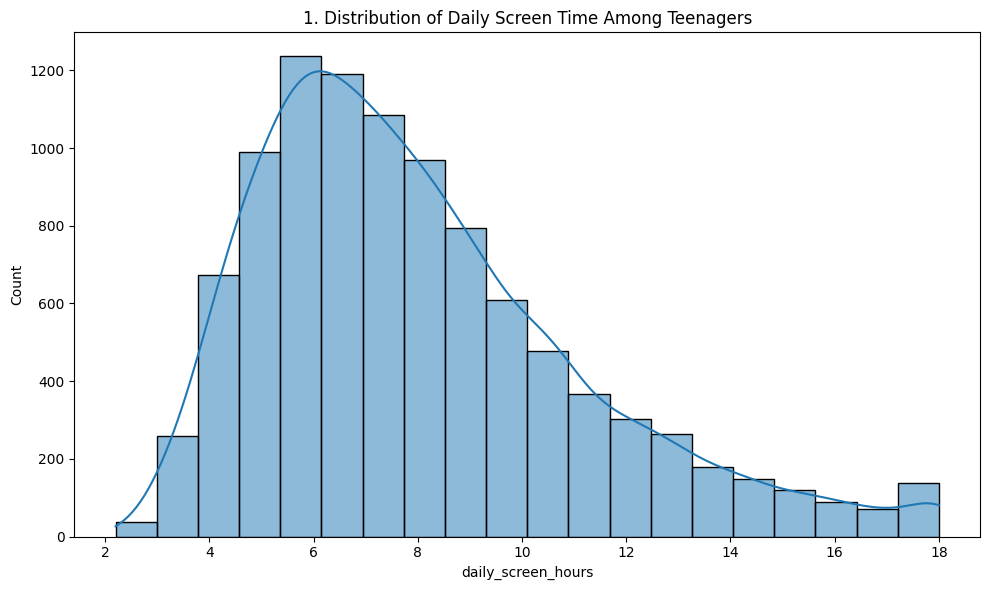

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='daily_screen_hours', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Daily Screen Time Among Teenagers')
show_fig()
plot_no += 1

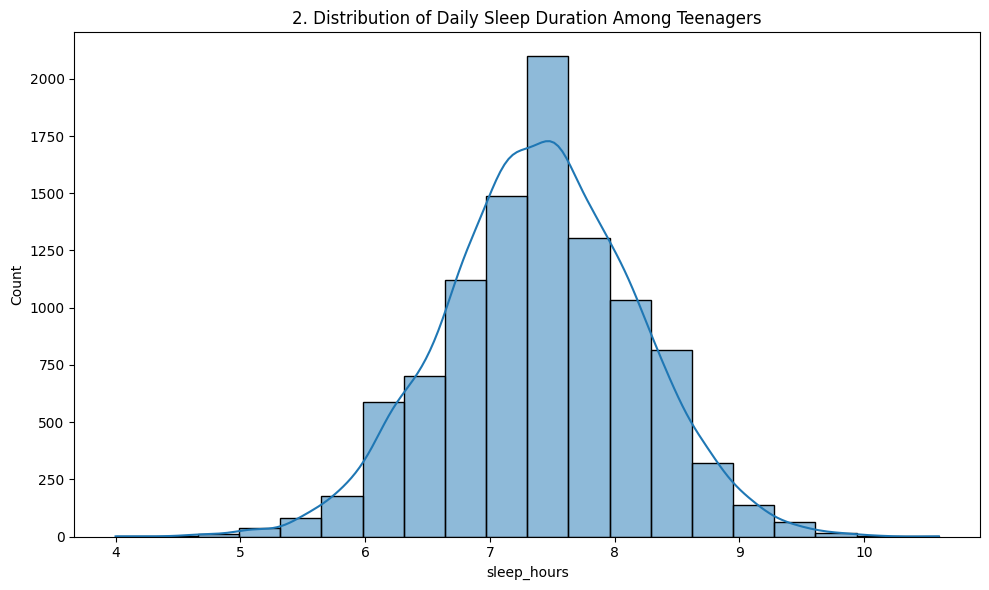

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='sleep_hours', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Daily Sleep Duration Among Teenagers')
show_fig()
plot_no += 1

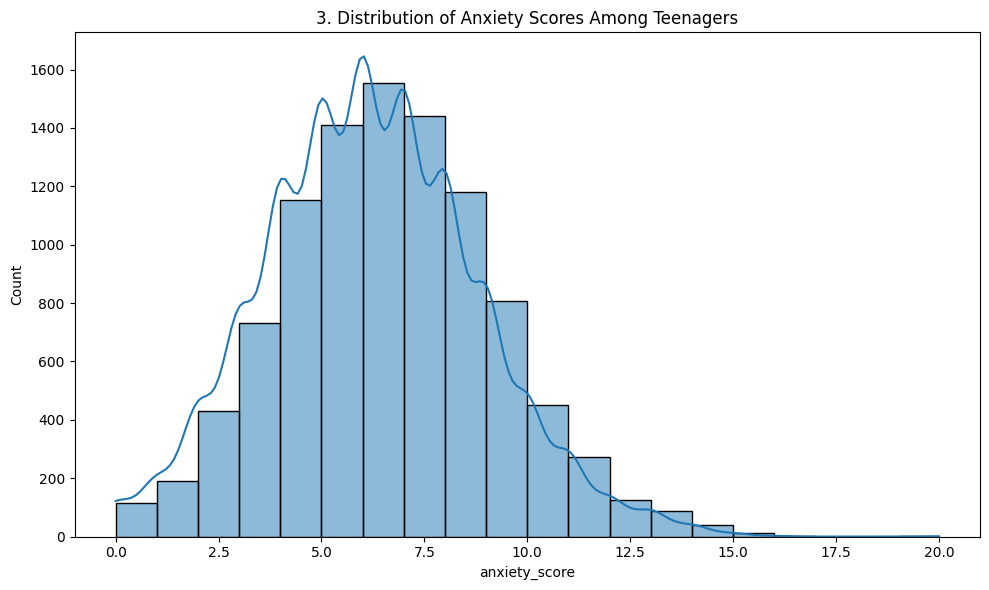

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='anxiety_score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Anxiety Scores Among Teenagers')
show_fig()
plot_no += 1

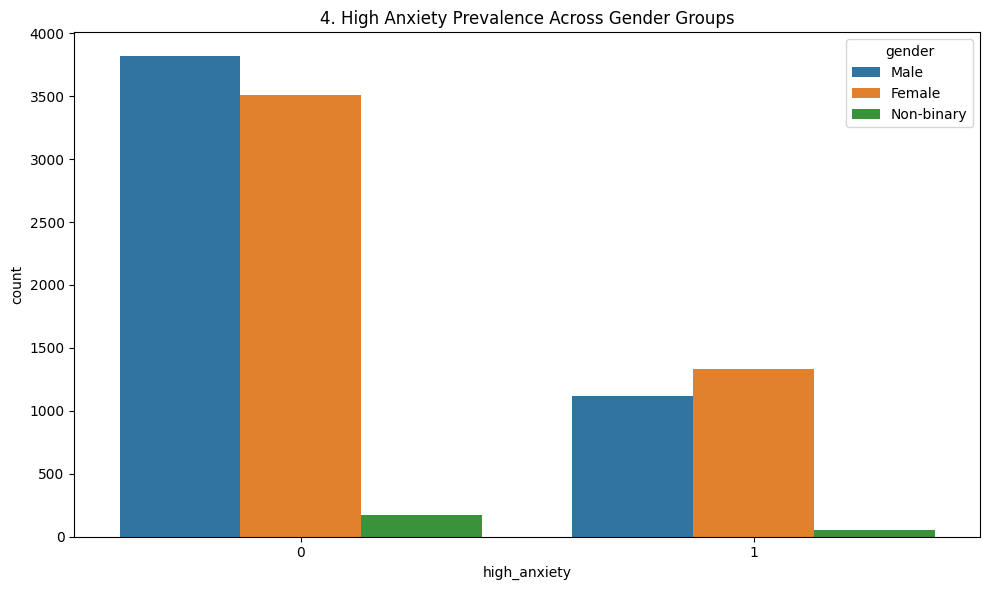

In [17]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='high_anxiety', hue='gender')
plt.title(f'{plot_no}. High Anxiety Prevalence Across Gender Groups')
show_fig()
plot_no += 1

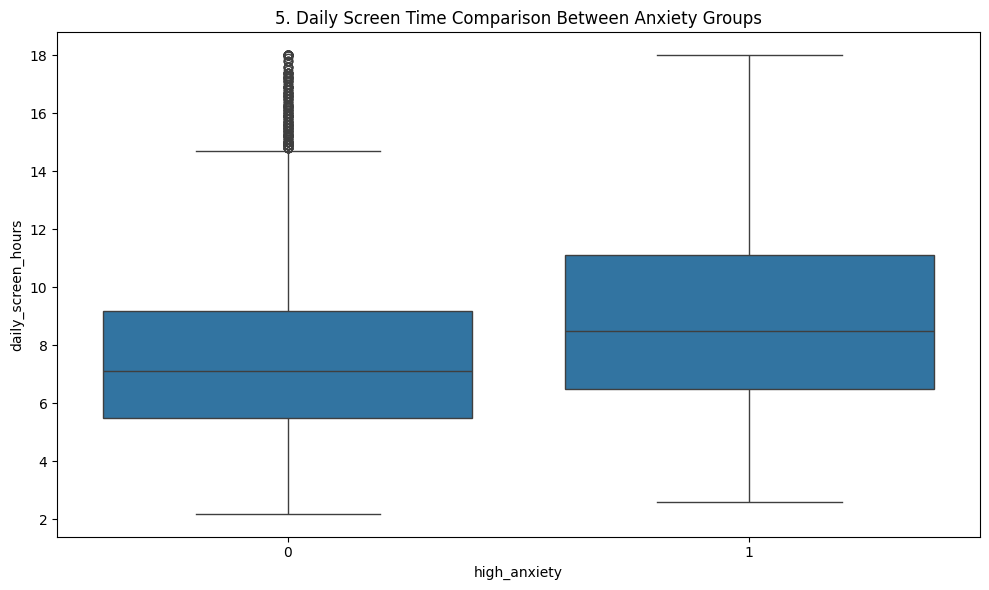

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='high_anxiety', y='daily_screen_hours')
plt.title(f'{plot_no}. Daily Screen Time Comparison Between Anxiety Groups')
show_fig()
plot_no += 1

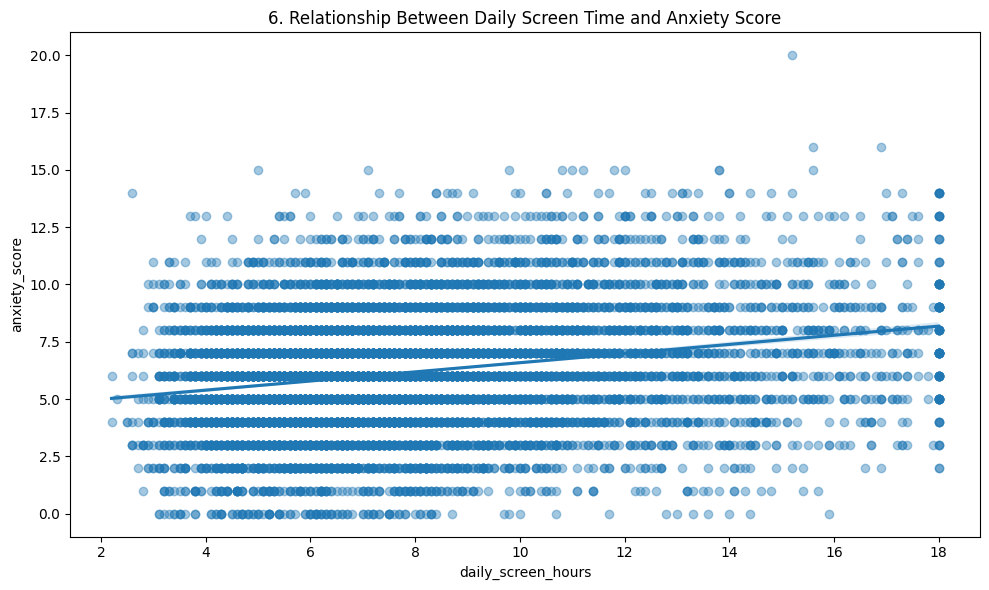

In [19]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='daily_screen_hours', y='anxiety_score', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Relationship Between Daily Screen Time and Anxiety Score')
show_fig()
plot_no += 1

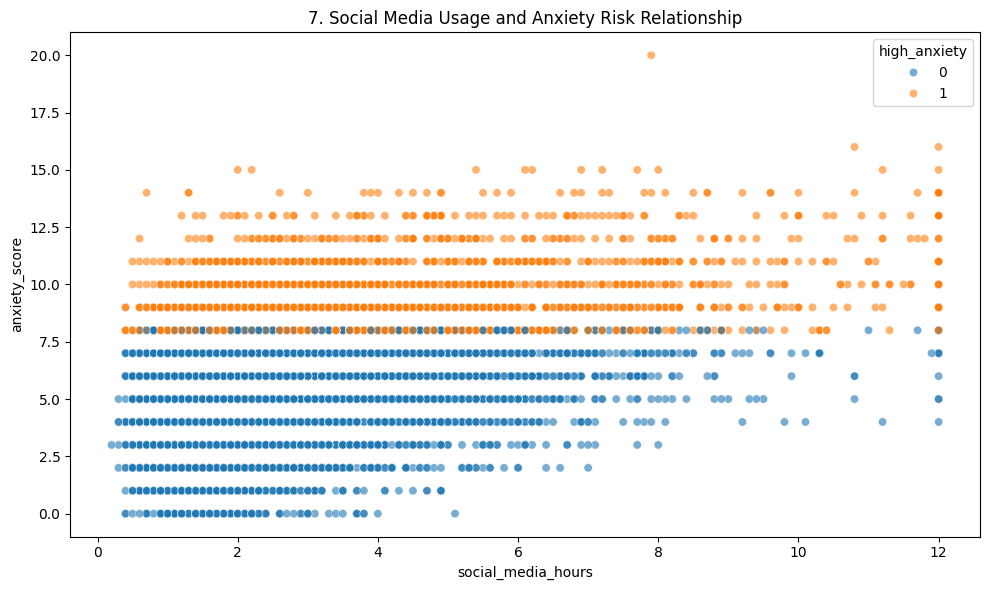

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_media_hours', y='anxiety_score', hue='high_anxiety', alpha=0.6)
plt.title(f'{plot_no}. Social Media Usage and Anxiety Risk Relationship')
show_fig()
plot_no += 1

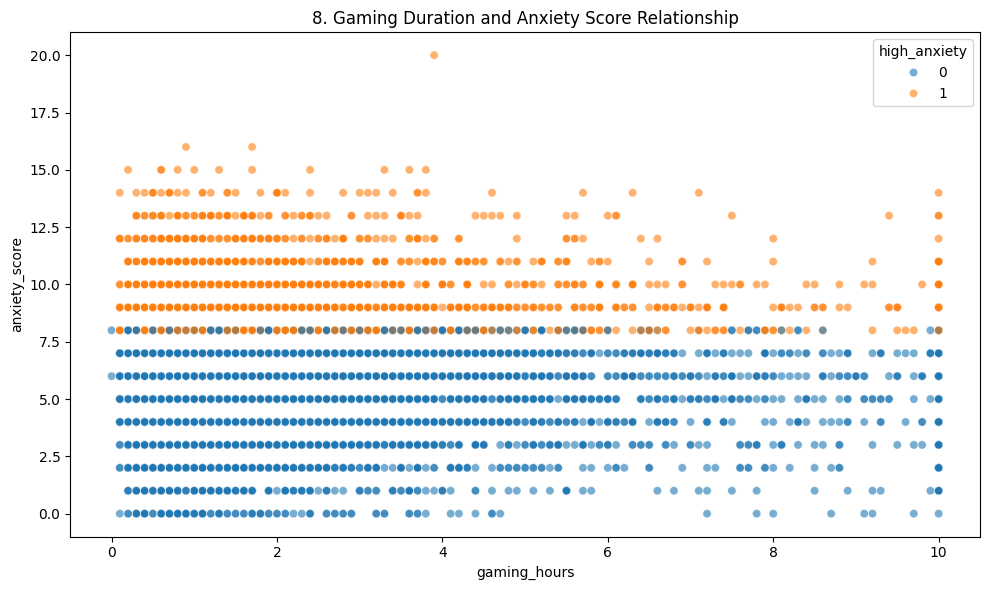

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='gaming_hours', y='anxiety_score', hue='high_anxiety', alpha=0.6)
plt.title(f'{plot_no}. Gaming Duration and Anxiety Score Relationship')
show_fig()
plot_no += 1

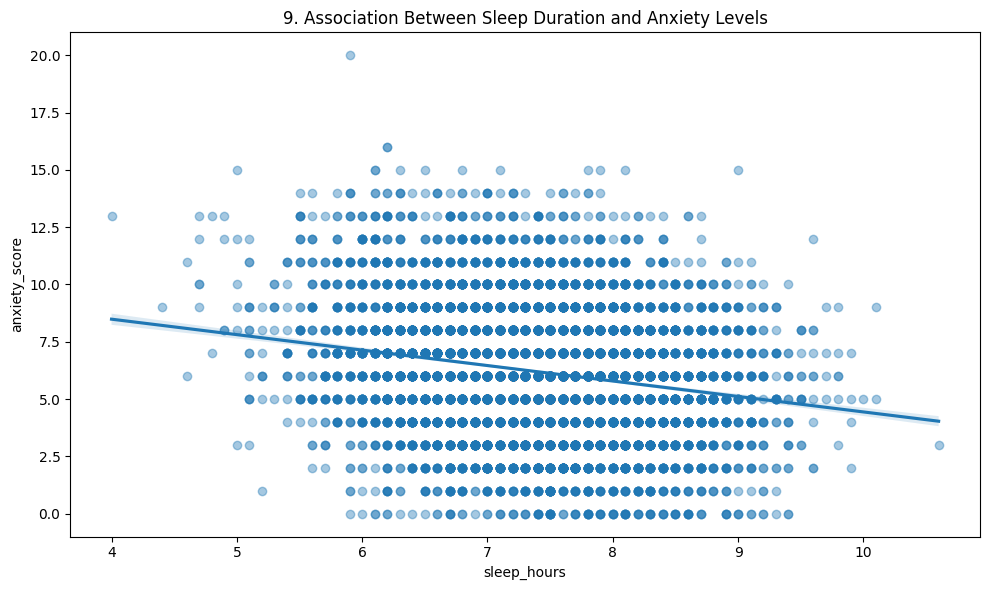

In [22]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='sleep_hours', y='anxiety_score', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Association Between Sleep Duration and Anxiety Levels')
show_fig()
plot_no += 1

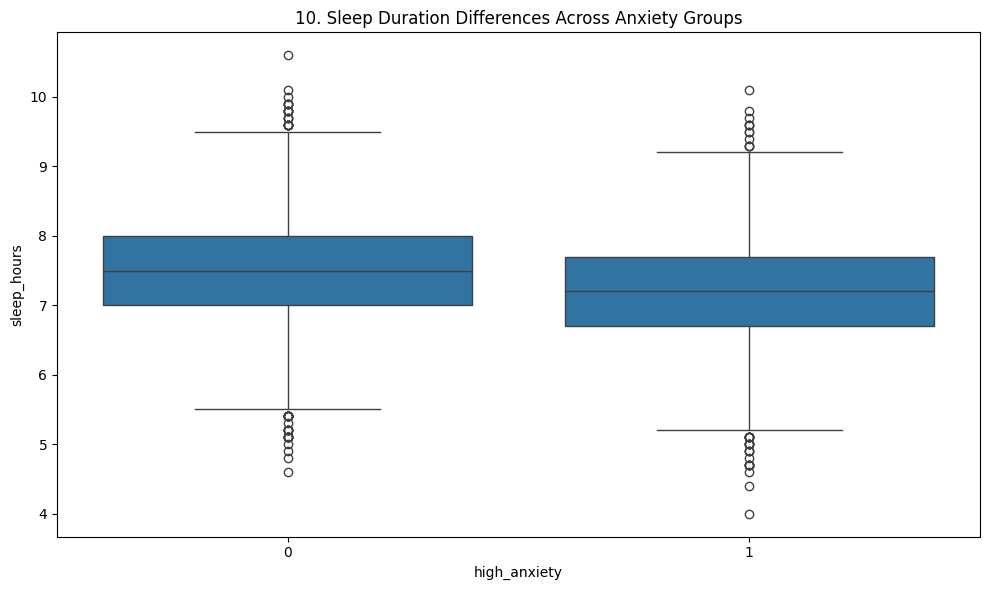

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='high_anxiety', y='sleep_hours')
plt.title(f'{plot_no}. Sleep Duration Differences Across Anxiety Groups')
show_fig()
plot_no += 1

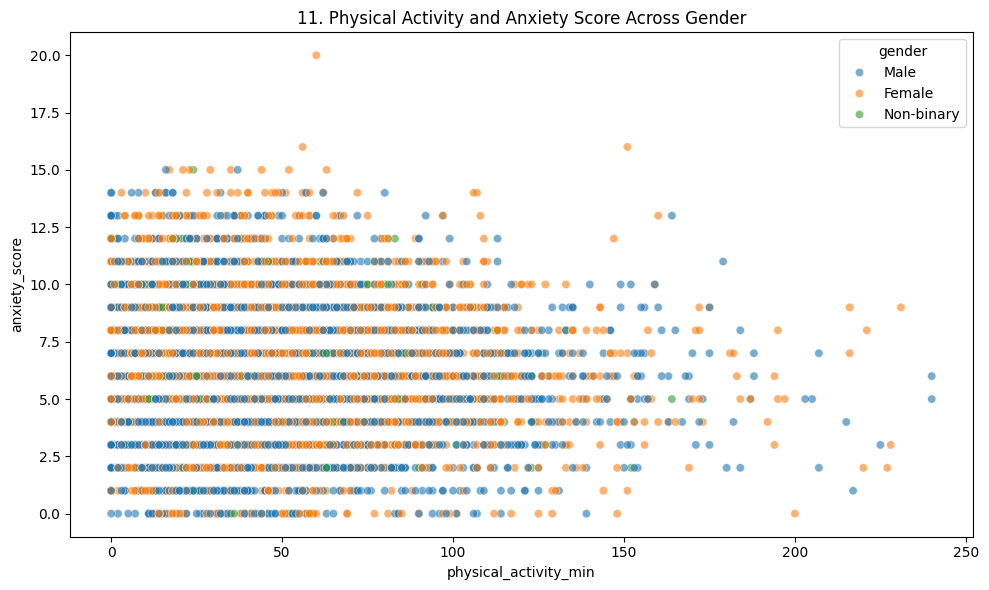

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='physical_activity_min', y='anxiety_score', hue='gender', alpha=0.6)
plt.title(f'{plot_no}. Physical Activity and Anxiety Score Across Gender')
show_fig()
plot_no += 1

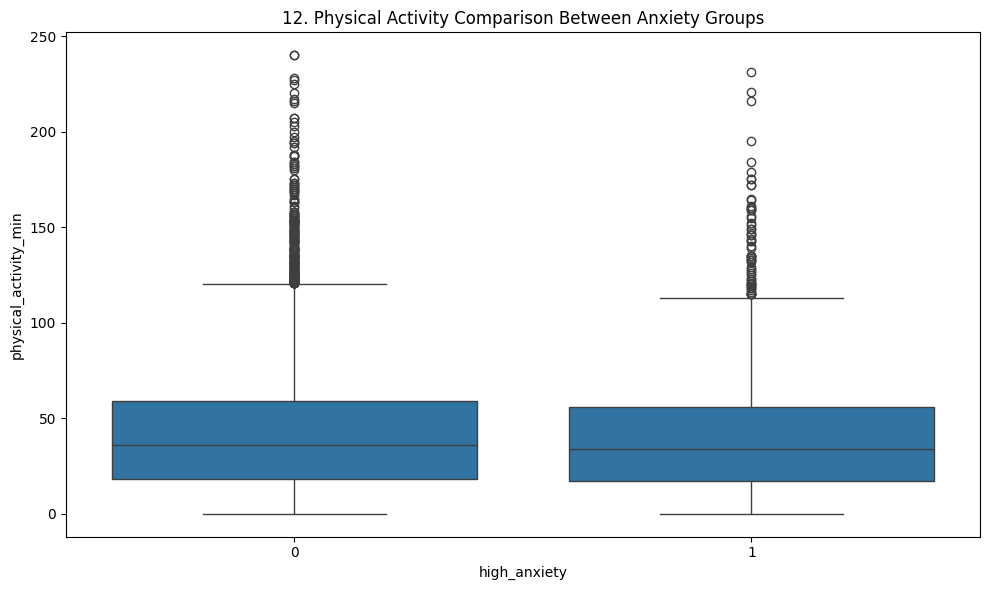

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='high_anxiety', y='physical_activity_min')
plt.title(f'{plot_no}. Physical Activity Comparison Between Anxiety Groups')
show_fig()
plot_no += 1

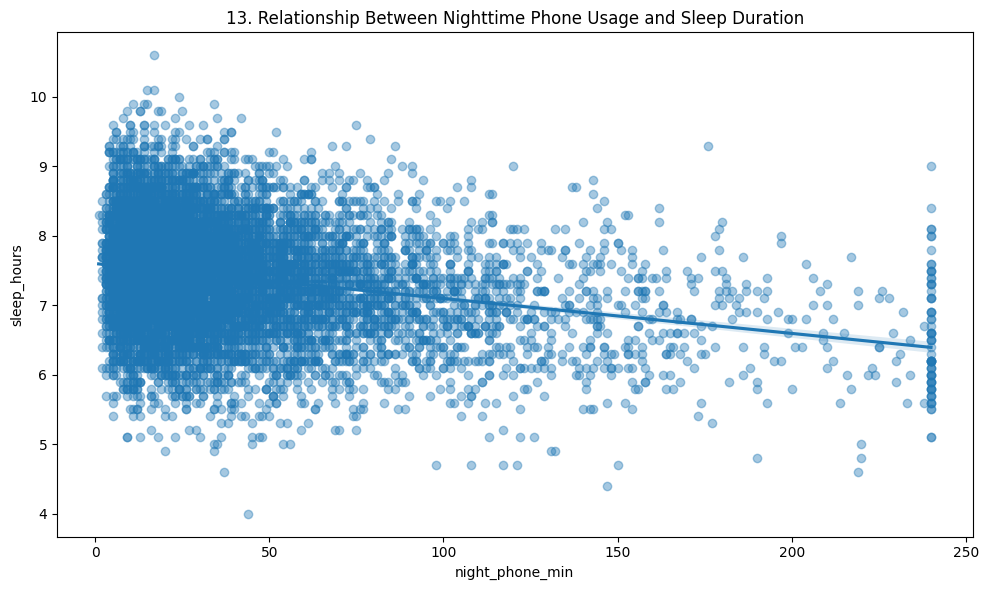

In [26]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='night_phone_min', y='sleep_hours', scatter_kws={'alpha':0.4})
plt.title(f'{plot_no}. Relationship Between Nighttime Phone Usage and Sleep Duration')
show_fig()
plot_no += 1

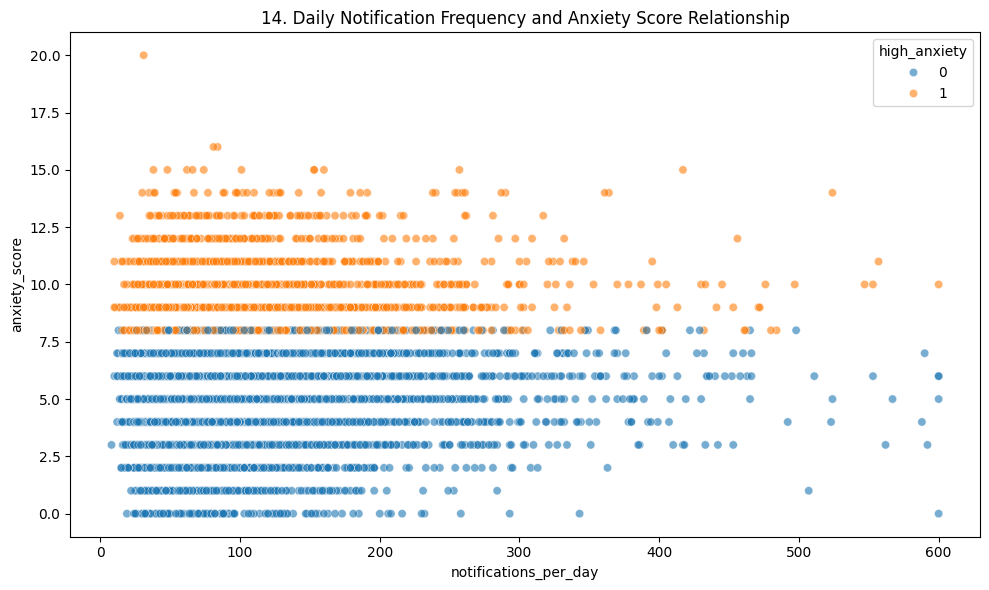

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='notifications_per_day', y='anxiety_score', hue='high_anxiety', alpha=0.6)
plt.title(f'{plot_no}. Daily Notification Frequency and Anxiety Score Relationship')
show_fig()
plot_no += 1

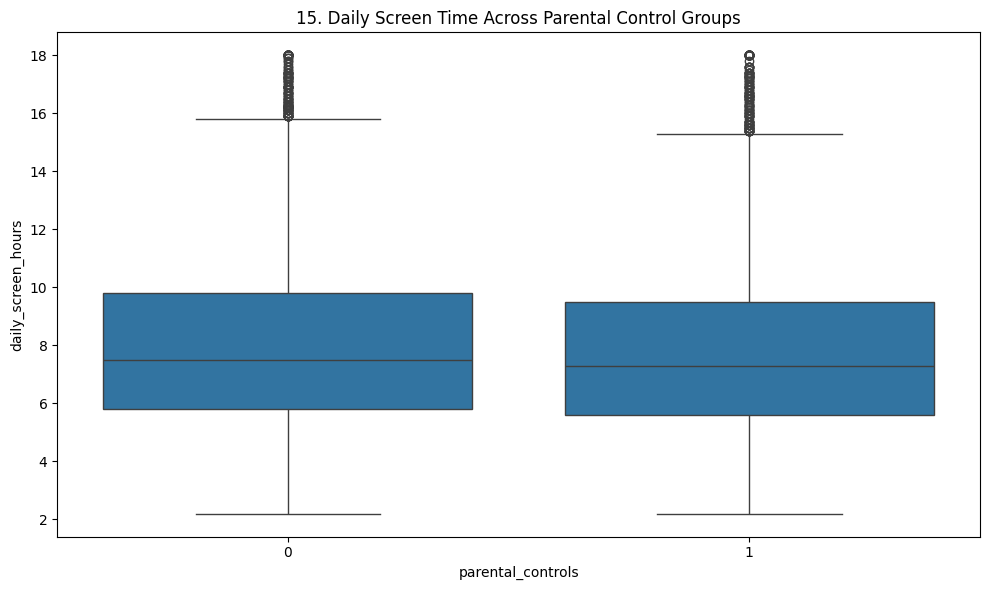

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='parental_controls', y='daily_screen_hours')
plt.title(f'{plot_no}. Daily Screen Time Across Parental Control Groups')
show_fig()
plot_no += 1

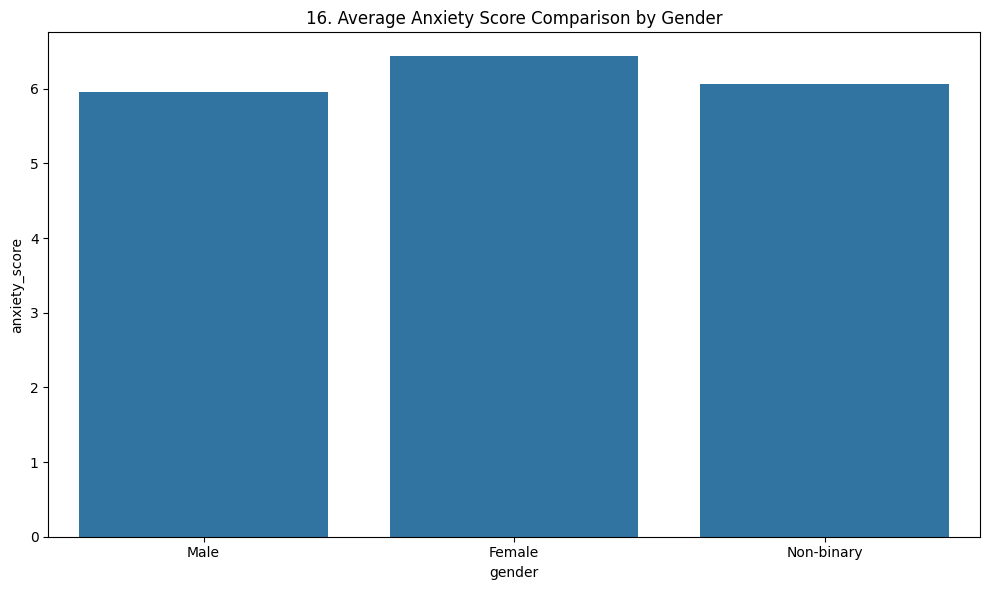

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='gender', y='anxiety_score', errorbar=None)
plt.title(f'{plot_no}. Average Anxiety Score Comparison by Gender')
show_fig()
plot_no += 1

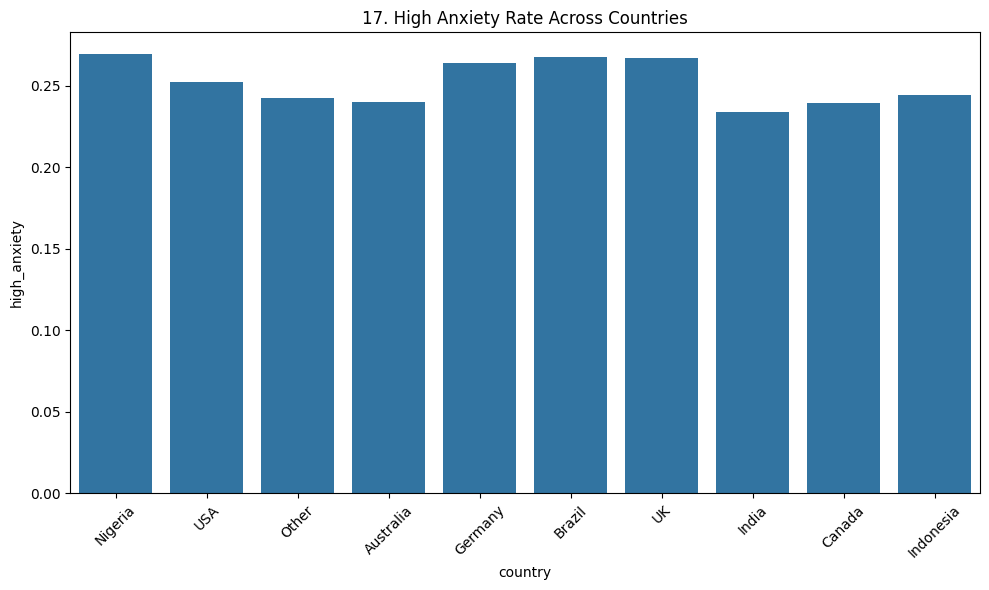

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='country', y='high_anxiety', errorbar=None)
plt.title(f'{plot_no}. High Anxiety Rate Across Countries')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

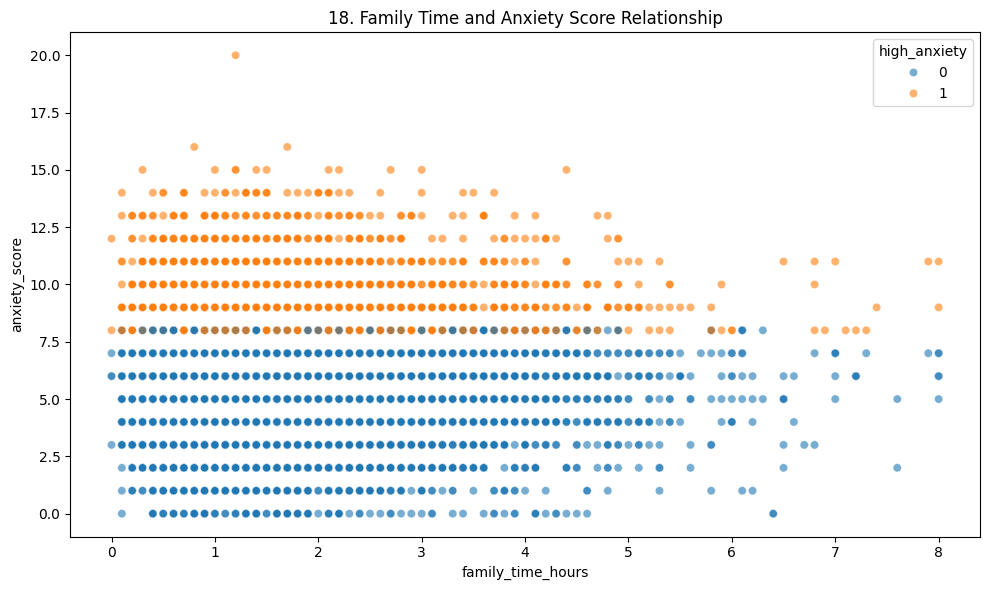

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='family_time_hours', y='anxiety_score', hue='high_anxiety', alpha=0.6)
plt.title(f'{plot_no}. Family Time and Anxiety Score Relationship')
show_fig()
plot_no += 1

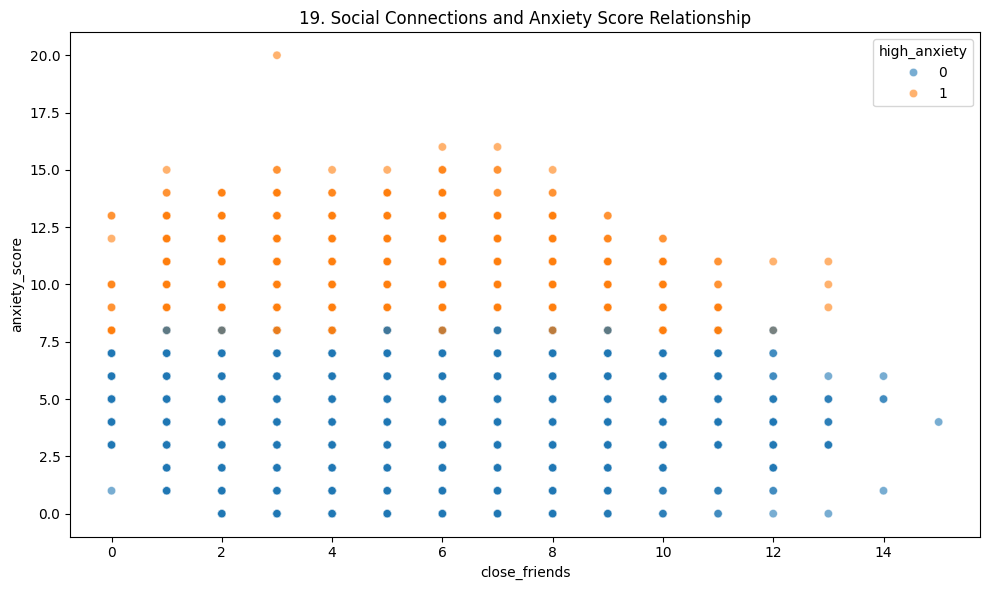

In [32]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='close_friends', y='anxiety_score', hue='high_anxiety', alpha=0.6)
plt.title(f'{plot_no}. Social Connections and Anxiety Score Relationship')
show_fig()
plot_no += 1

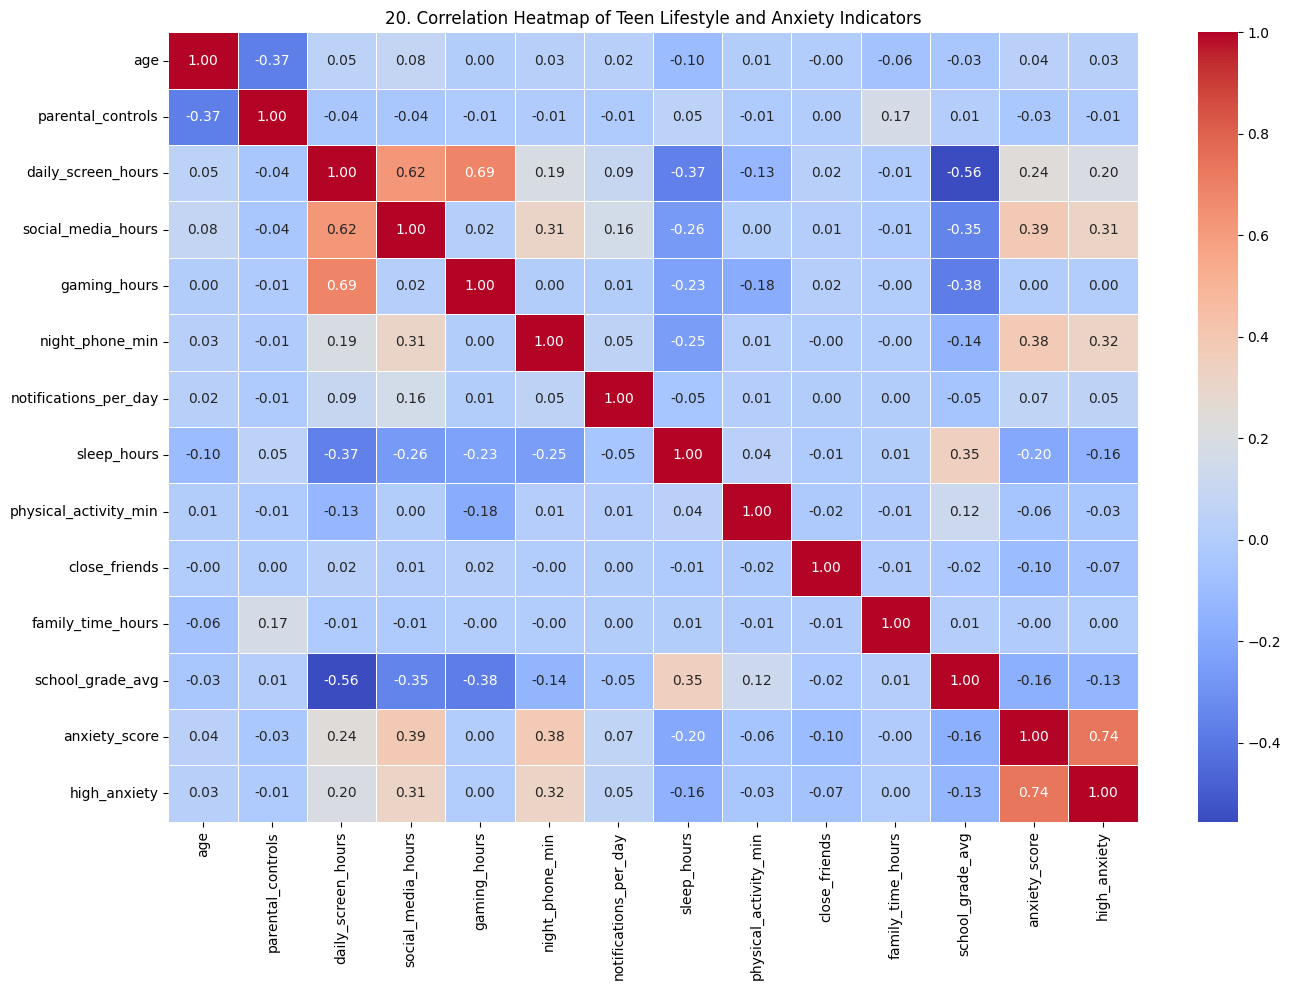

In [33]:
corr = df.select_dtypes(include='number').corr()

fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Teen Lifestyle and Anxiety Indicators')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [34]:
X = df.drop(columns=['teen_id', 'gender', 'country', 'high_anxiety'])
y = df['high_anxiety']

## Split dataset

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Scale features

In [36]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Train classification model

In [37]:
model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

## Make predictions

In [38]:
y_pred = model.predict(X_test)

## Evaluate model

In [39]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.25 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1500
           1       0.84      1.00      0.91       500

    accuracy                           0.95      2000
   macro avg       0.92      0.97      0.94      2000
weighted avg       0.96      0.95      0.95      2000



## Plot confusion matrix

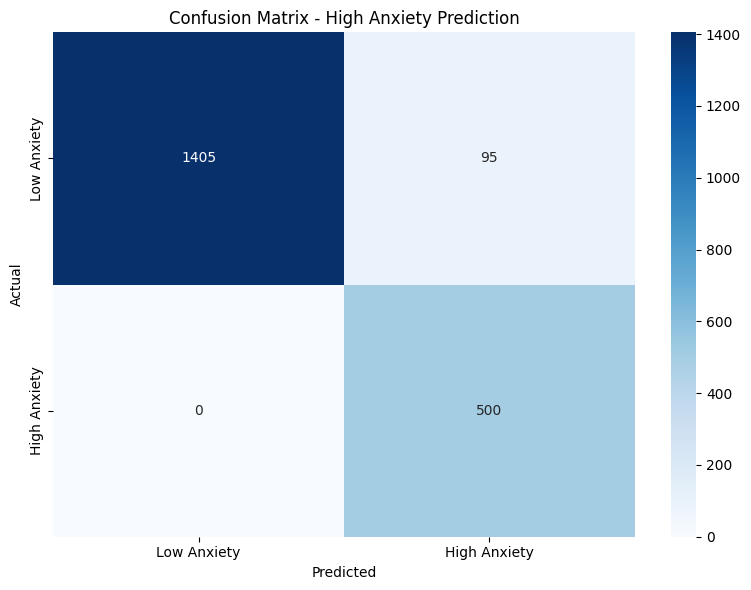

In [40]:
fig = plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low Anxiety', 'High Anxiety'],
            yticklabels=['Low Anxiety', 'High Anxiety'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - High Anxiety Prediction')
show_fig()
